# Is the growth captured by $\lambda$? The growth rate along the sweeps

**The question.** The envelope law says $\dot a = \left[\lambda(\bar P,\delta) - \dot\omega/2\omega\right]a$: at every instant the oscillation grows or decays at the rate $\lambda$ evaluated at the current slow state. Is that true in the full simulation — not just on average over a run, but cycle by cycle, through the initial growth, the approach to the steady oscillation, and the collapse of the stall cases?

**How it is tested.** For each of the 37 settings of `parameter_sweeps_check.ipynb`, the full simulation is run and reduced to per-cycle values of the mean pressure, mean temperature, mean piston position and the half swing $\delta$. Two growth rates are then compared at every cycle:

- **the formula**, $\lambda = -\dfrac{b}{2m} + \dfrac{g}{2}\dfrac{k_{cv}}{k_{cv}+k_{pass}}$ with $g = -\dfrac{C_f}{\bar V_{cv}}\left(T_{in}N_{in} + \bar T N_{out}\right)$ and the gains $N$ from the describing-function integrals — evaluated at the *simulated* slow state (nothing from the averaged model's own ODEs enters, so this is a test of the growth-rate formula alone);
- **the measurement**, the logarithmic rate of the simulated envelope corrected for the drift terms of the envelope law: $\lambda_{meas} = \dfrac{d\ln\delta}{dt} + \dfrac{\dot\omega}{2\omega} - \dfrac{\dot k_{cv}}{k_{cv}}$ (the last two terms convert the pressure envelope back to the piston amplitude, since $\delta = k_{cv}a/A$ and $a \propto \omega^{-1/2}$ under drift).

$\lambda_0$ denotes the initial growth rate, averaged over cycles 2 to 4.

**Reading in advance.** The formula tracks the measured rate at every cycle of every run: initial rates agree to a few percent across the whole set (from $-7$ to $+17$ per second), both go to zero together on the steady oscillations, and both swing to $-30$ to $-60$ per second at the turnover of the stall cases. One thing $\lambda$ does *not* capture, and is not meant to: the outcome. Most stall cases have $\lambda_0 > 0$ — they grow first and die later, when the filling resonator drags $\lambda$ negative; whether that happens is the slow equations' business, not $\lambda$'s. Section 5 plots $\lambda$ against the outcome directly and shows what does sort the runs: the number of e-folds $\lambda$ can deliver before the filling resonator takes the drive away, against the number the kick needs — and section 5.1 gives that number in closed form.

Runtime: about 8 minutes.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4)


class Model:
    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI)

    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); mr = dP <= 0
        out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo]); out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def run_full(self, t_end, fs=10000.0, rtol=1e-7):
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        te = np.arange(0.0, t_end, 1.0 / fs)
        sol = solve_ivp(self.full_ode, (0.0, t_end), [self.x0, self.v0, M0, self.cv * M0 * self.T0],
                        t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
        x, v, M, E = sol.y; T = E / (self.cv * M)
        return sol.t, M * self.R * T / (self.V0_cv + x * self.A_neck), T, x

    def F0F1(self, dPbar, delta):
        vals = self.reed_vec(dPbar + delta * self.CPS)
        return vals.mean(), 2.0 * (vals * self.CPS).mean()

    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def lam(self, Pb, Tb, xb, delta):
        """Growth rate (20) with the finite-amplitude gain (17), at a given slow state (Pbar, Tbar, mean piston position, delta)."""
        Vc = self.V0_cv + self.A_neck * xb; Vp = self.V0_pass - self.A_neck * xb
        Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pp * self.A_neck ** 2 / Vp
        w = np.sqrt((kcv + kp) / self.m_gas)
        if delta > 1.0:
            F0i, F1i = self.F0F1(self.P_in - Pb, delta); F0o, F1o = self.F0F1(Pb - self.P_out, delta)
            Ni, No = F1i / delta, F1o / delta
        else:
            h = 1.0
            Ni = (self.reed(self.P_in - Pb + h) - self.reed(self.P_in - Pb - h)) / (2 * h)
            No = (self.reed(Pb - self.P_out + h) - self.reed(Pb - self.P_out - h)) / (2 * h)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Tb * No)
        return -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp), g, kcv, w


def per_cycle(t, P, T, x):
    """Cycle edges from upward crossings of P about a peak/trough mean; per-cycle means, half swing, frequency."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    rows = []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        rows.append((0.5 * (a + b), P[m].mean(), T[m].mean(), x[m].mean(), 0.5 * (P[m].max() - P[m].min()), 1.0 / (b - a)))
    return [np.array(c) for c in zip(*rows)]


def smooth(y, n=5):
    return np.convolve(np.pad(y, (n // 2, n // 2), mode='edge'), np.ones(n) / n, mode='valid')


def analyse(model, t_end):
    t, P, T, x = model.run_full(t_end)
    tm, Pm, Tm, xm, half, freq = per_cycle(t, P, T, x)
    live = half > 0.1 * half.max()
    lam_an = np.zeros(len(tm)); kcv = np.zeros(len(tm)); w = np.zeros(len(tm))
    for i in range(len(tm)):
        lam_an[i], _, kcv[i], w[i] = model.lam(Pm[i], Tm[i], xm[i], half[i])
    ld = np.log(np.maximum(half, 1e-3))
    lam_meas = smooth(np.gradient(ld, tm), 5) + 0.5 * np.gradient(np.log(w), tm) - np.gradient(np.log(kcv), tm)
    scale = float(np.sqrt(np.mean(lam_an[live] ** 2))); sig = live & (np.abs(lam_an) > 0.1 * scale)
    late = tm > t_end - 0.1
    res = dict(lam0_an=float(np.mean(lam_an[1:4])), lam0_meas=float(np.mean(lam_meas[1:4])),
               lam0_nominal=float(model.lam(model.P0, model.T0, 0.0, model.geom(model.P0)[2] * model.v0 / model.geom(model.P0)[4] / model.A_neck)[0]),
               lam_rms_diff=float(np.sqrt(np.mean((lam_meas[live] - lam_an[live]) ** 2))), lam_scale=scale,
               lam_sign_agree=float(np.mean(np.sign(lam_meas[sig]) == np.sign(lam_an[sig]))) if sig.any() else np.nan,
               lam_min_an=float(lam_an[live].min()), lam_max_an=float(lam_an[live].max()),
               sustained=bool(late.any() and half[late].mean() > 1e3))
    return res, dict(tm=tm, half=half, Pm=Pm, lam_an=lam_an, lam_meas=lam_meas, live=live)


def t_end_for(model):
    Mtot = model.P0 * (model.V0_cv + model.V0_pass) / (model.R * model.T0)
    return float(np.clip(1.5 * Mtot / model.m_max, 1.0, 6.0))

In [2]:
SWEEPS = {
    'm_max':   ('valve capacity  mdot_max [kg/s]',   [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed bias factor  zeta',             [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping  b [N s/m]',          [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume  V0_pass [m^3]',      [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass  m [kg]',                [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick  v0 [m/s]',             [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure  P_in [Pa]',          [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}
FEATURED = [('v0', 5.0), ('m_max', 4e-3), ('zeta', 1.2), ('v0', 20.0), ('b_gas', 0.02), ('P_in', 6.2e5)]
rows, kept = [], {}
tic = time.time()
for key, (label, vals) in SWEEPS.items():
    for v in vals:
        model = Model(**{key: v}); te = t_end_for(model)
        res, tr = analyse(model, te)
        rows.append(dict(sweep=key, value=v, **res))
        kept[(key, v)] = tr
        print('%-8s = %-8g  lambda_0 formula/measured %6.2f/%6.2f 1/s   rms diff along run %5.2f 1/s   range of lambda [%6.1f, %6.1f]  [%3.0f s]'
              % (key, v, res['lam0_an'], res['lam0_meas'], res['lam_rms_diff'], res['lam_min_an'], res['lam_max_an'], time.time() - tic))
df = pd.DataFrame(rows)

m_max    = 0.00025   lambda_0 formula/measured   0.46/  0.46 1/s   rms diff along run  0.06 1/s   range of lambda [  -8.9,    0.5]  [ 18 s]


m_max    = 0.0005    lambda_0 formula/measured   2.55/  2.52 1/s   rms diff along run  0.05 1/s   range of lambda [   0.0,    2.6]  [ 30 s]


m_max    = 0.001     lambda_0 formula/measured   6.53/  6.36 1/s   rms diff along run  0.07 1/s   range of lambda [  -0.0,    6.8]  [ 37 s]


m_max    = 0.002     lambda_0 formula/measured  13.09/ 12.29 1/s   rms diff along run  0.16 1/s   range of lambda [  -0.0,   15.1]  [ 40 s]


m_max    = 0.004     lambda_0 formula/measured  17.48/ 16.24 1/s   rms diff along run  0.78 1/s   range of lambda [  -0.1,   30.8]  [ 43 s]


...

P_in     = 585000    lambda_0 formula/measured  -3.85/ -4.09 1/s   rms diff along run  0.83 1/s   range of lambda [ -39.8,   -3.8]  [380 s]


P_in     = 590000    lambda_0 formula/measured   2.21/  1.88 1/s   rms diff along run  0.61 1/s   range of lambda [ -38.6,    4.1]  [406 s]


P_in     = 600000    lambda_0 formula/measured   6.53/  6.36 1/s   rms diff along run  0.07 1/s   range of lambda [  -0.0,    6.8]  [413 s]


P_in     = 620000    lambda_0 formula/measured   4.42/  4.39 1/s   rms diff along run  0.17 1/s   range of lambda [ -25.5,    4.5]  [435 s]


P_in     = 650000    lambda_0 formula/measured   1.48/  1.50 1/s   rms diff along run  0.14 1/s   range of lambda [ -26.9,    1.9]  [456 s]


## 1. Table: initial growth rate and agreement along the run

$\lambda_0$ (nominal) is the formula at the nominal initial state ($\bar P = P_0$, $\delta_0 = k_{cv}v_0/\omega_0 A$); the next two columns compare formula and measurement at the same cycles (2 to 4) of the simulation. "rms diff" is the root-mean-square of formula minus measurement over the cycles where the oscillation is alive; "scale" is the rms of $\lambda$ itself over the same cycles, for comparison. Negative $\lambda_0$ means the kick decays from the start.

In [3]:
tab = df.copy()
tab['outcome'] = np.where(tab.sustained, 'steady', 'stall')
show = tab[['sweep', 'value', 'outcome', 'lam0_nominal', 'lam0_an', 'lam0_meas', 'lam_rms_diff', 'lam_scale', 'lam_min_an', 'lam_max_an']]
show.columns = ['sweep', 'value', 'outcome', 'lambda_0 nominal [1/s]', 'lambda_0 formula [1/s]', 'lambda_0 measured [1/s]',
                'rms diff [1/s]', 'scale [1/s]', 'min lambda [1/s]', 'max lambda [1/s]']
pd.set_option('display.width', 220)
show.round(2)

,sweep,value,outcome,lambda_0 nominal [1/s],lambda_0 formula [1/s],lambda_0 measured [1/s],rms diff [1/s],scale [1/s],min lambda [1/s],max lambda [1/s]
0,m_max,0.00,stall,0.46,0.46,0.46,0.06,2.54,-8.88,0.46
1,m_max,0.00,steady,2.59,2.55,2.52,0.05,0.43,0.00,2.58
2,m_max,0.00,steady,6.85,6.53,6.36,0.07,1.07,-0.02,6.79
3,m_max,0.00,steady,15.37,13.09,12.29,0.16,2.29,-0.03,15.10
4,m_max,0.00,steady,32.40,17.48,16.24,0.78,3.98,-0.08,30.78
5,zeta,0.40,stall,-0.22,-0.22,-0.27,0.08,1.69,-4.80,-0.21
6,zeta,0.50,steady,3.03,2.95,2.88,0.13,0.70,0.02,3.01
7,zeta,0.60,steady,6.85,6.53,6.36,0.07,1.07,-0.02,6.79
8,zeta,0.80,steady,10.62,8.65,8.48,0.07,1.24,-0.01,10.01
9,zeta,1.00,steady,9.08,8.05,7.88,0.07,1.20,-0.01,8.81


## 2. Initial growth rate: formula against measurement, all 37 runs

One point per run. The line is perfect agreement. The spread of $\lambda_0$ across the sweeps — from $-7$ per second (a kick larger than the steady amplitude, which must decay to it) to $+17$ per second (four times the baseline valve capacity) — is reproduced by the formula to a few percent.

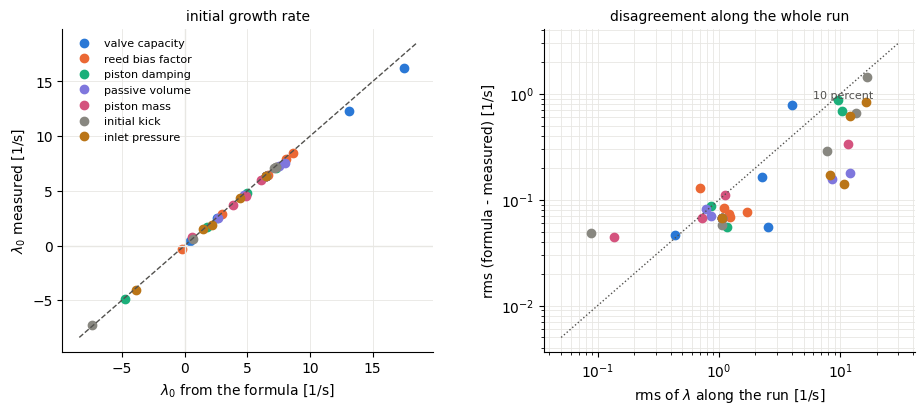

In [4]:
sweep_names = list(SWEEPS)
cols = dict(zip(sweep_names, [BLUE, ORANGE, AQUA, '#7f77dd', '#d4537e', '#888780', '#ba7517']))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2)); fig.subplots_adjust(wspace=0.3)
ax = axs[0]
for k in sweep_names:
    d = df[df.sweep == k]
    ax.plot(d.lam0_an, d.lam0_meas, 'o', color=cols[k], ms=6, label=SWEEPS[k][0].split('  ')[0])
lim = (df.lam0_an.min() - 1, df.lam0_an.max() + 1)
ax.plot(lim, lim, '--', color=INK2, lw=1); ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
ax.set_xlabel(r'$\lambda_0$ from the formula [1/s]'); ax.set_ylabel(r'$\lambda_0$ measured [1/s]'); ax.set_title('initial growth rate', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax = axs[1]
for k in sweep_names:
    d = df[df.sweep == k]
    ax.plot(d.lam_scale, d.lam_rms_diff, 'o', color=cols[k], ms=6)
ax.plot([0.05, 30], [0.05 * 0.1, 30 * 0.1], ':', color=INK2, lw=1); ax.text(6, 0.9, '10 percent', color=INK2, fontsize=8)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel(r'rms of $\lambda$ along the run [1/s]'); ax.set_ylabel('rms (formula - measured) [1/s]')
ax.set_title('disagreement along the whole run', fontsize=10)
for a in axs:
    for sp in ['top', 'right']: a.spines[sp].set_visible(False)
    a.grid(color=GRID, lw=0.6, which='both')
plt.show()

## 3. $\lambda$ along the run, six cases

Top row: growth rate — the formula evaluated at the simulated state (line) and the measured envelope rate (dots). Bottom row: the envelope itself, for orientation. Left to right: the baseline (grows, saturates, $\lambda \to 0$ on the steady oscillation); four times the valve capacity (fast growth, 30 per second); $\zeta = 1.2$ (both valves closed at the mean — the tangent slope is zero there, so the whole growth rate is the finite-amplitude gain); a kick of 20 m/s (the initial amplitude exceeds the steady one, so $\lambda_0 < 0$ and the envelope decays *down* to the same steady oscillation); and two stall cases, where $\lambda$ turns sharply negative as the resonator fills and both models agree on when.

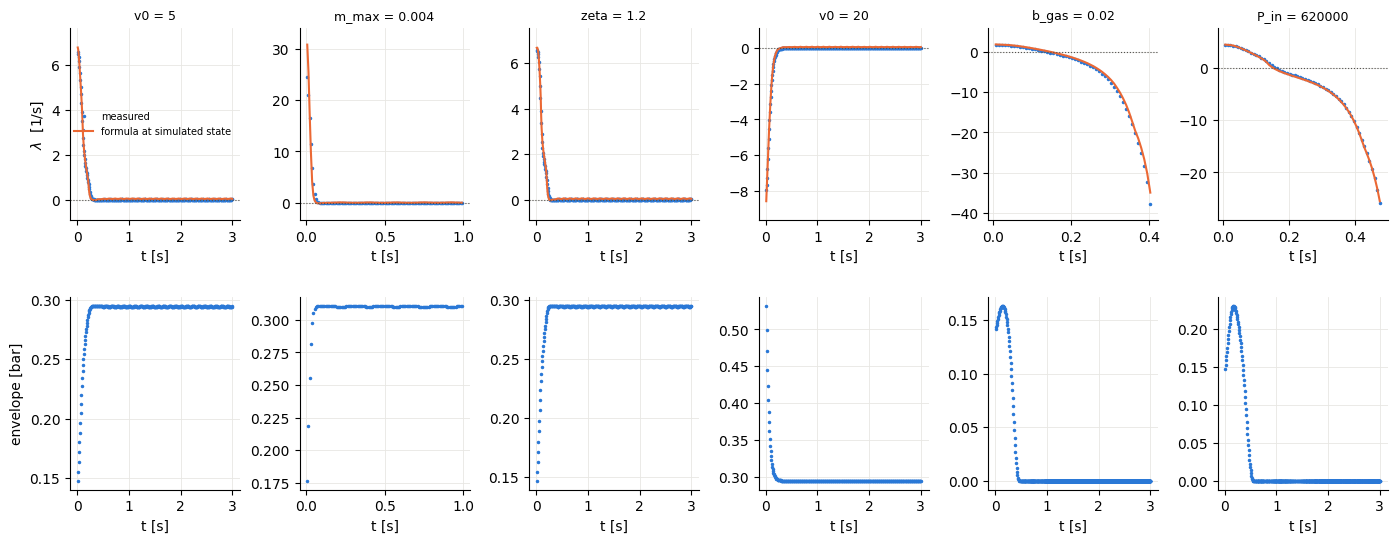

In [5]:
fig, axs = plt.subplots(2, 6, figsize=(17, 6)); fig.subplots_adjust(wspace=0.35, hspace=0.4)
for j, (key, v) in enumerate(FEATURED):
    tr = kept[(key, v)]; L = tr['live']
    ax = axs[0, j]
    ax.plot(tr['tm'][L], tr['lam_meas'][L], '.', color=BLUE, ms=3, label='measured')
    ax.plot(tr['tm'][L], tr['lam_an'][L], color=ORANGE, lw=1.5, label='formula at simulated state')
    ax.axhline(0, color=INK2, lw=0.8, ls=':')
    lo, hi = min(tr['lam_an'][L].min(), tr['lam_meas'][L].min()), max(tr['lam_an'][L].max(), tr['lam_meas'][L].max())
    ax.set_ylim(lo - 0.1 * (hi - lo) - 0.2, hi + 0.1 * (hi - lo) + 0.2)
    ax.set_title('%s = %g' % (key, v), fontsize=9); ax.set_xlabel('t [s]')
    if j == 0: ax.set_ylabel(r'$\lambda$  [1/s]'); ax.legend(frameon=False, fontsize=7)
    ax = axs[1, j]
    ax.plot(tr['tm'], tr['half'] / 1e5, '.', color=BLUE, ms=3)
    ax.set_xlabel('t [s]')
    if j == 0: ax.set_ylabel('envelope [bar]')
for ax in axs.ravel():
    for sp in ['top', 'right']: ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6)
plt.show()

## 4. What this says

Yes: the growth of the oscillation is captured by $\lambda$, and not only on average. Evaluated at the simulated slow state, the formula $\lambda = -b/2m + (g/2)\,k_{cv}/(k_{cv}+k_{pass})$ with the finite-amplitude gains reproduces the measured rate of the envelope cycle by cycle, in every one of the 37 settings: the initial rate to a few percent over a range from $-7$ to $+17$ per second, the fall of $\lambda$ toward zero as the amplitude saturates (the residual on the steady oscillation, a few hundredths per second, is the 2 percent envelope offset seen in the sweep notebook), and the plunge to $-30$ to $-60$ per second when a stall case turns over. Since the comparison feeds the *simulated* mean pressure, temperature, piston position and amplitude into the formula, it tests the growth-rate formula on its own, separately from the slow equations that predict how that state evolves.

Two things to keep apart. First, $\lambda$ is a rate, not a verdict: its sign at the start says whether the kick grows initially, and most stall cases do grow initially ($\lambda_0 > 0$) before the filling resonator drags $\lambda$ negative. Whether that happens before the amplitude is large enough to hold the mean in place is decided by the slow equations, and near that boundary the outcome is sensitive at the level of the dropped terms (the $v_0 = 2.5$ m/s case of the sweep notebook); section 5 below puts numbers on this. Second, $\lambda$ depends on the amplitude through the gains $N(\delta)$: it is largest for a small oscillation and falls as the swing grows, which is exactly why the steady oscillation exists — it sits where $\lambda(\bar P,\delta) = 0$. A kick larger than the steady amplitude starts with $\lambda < 0$ and decays to the same steady state from above.

## 5. $\lambda$ against the outcome: growth or stall

Four views of the same 37 runs, coloured by what the full simulation did in the end (blue: steady oscillation, orange: stall).

**(a)** The initial growth rate $\lambda_0$ of each run against its outcome. If $\lambda_0$ decided the outcome, the two rows would not overlap.

**(b)** $\lambda$ along every run (the formula at the simulated state, as in section 3), on a logarithmic time axis so that the fast and the slow cases can be seen together.

**(c)** The path of every run in the plane of mean pressure $\bar P$ and amplitude $\delta$. The steady runs all end at the same point; the stall runs turn over (rings, where $\lambda = 0$) and then slide to a state where the valves are shut.

**(d)** A quantity that does sort the outcomes, built from $\lambda$. Take the slow equations with no oscillation at all ($a = 0$): they describe how the mean pressure drifts from $P_0$ (toward $P_{in}$ in most settings, toward $P_{out}$ when the outlet passes more than the inlet). Along that drift, evaluate the small-amplitude growth rate $\lambda_{lin}(t) = \lambda(\bar P(t), \delta \to 0)$ and integrate it up to the moment $t_1$ where it first turns negative — the moment the valves stop driving and start damping:

$$B = \int_0^{t_1} \lambda_{lin} dt$$

$B$ is the number of e-folds a small oscillation can gain before the drifting mean pressure takes the drive away. Against it stands the number of e-folds the kick needs to reach the steady amplitude, $\ln(\delta_{steady}/\delta_0)$, with $\delta_0 = k_{cv}v_0/\omega_0 A$ the amplitude of the kick and $\delta_{steady}$ the amplitude the steady runs settle to (the median over the steady runs is used; they all lie within 0.28 to 0.31 bar). Growth needed above growth available means the mean pressure drifts away before the oscillation is large enough to hold it, and the run should stall. Two settings have no small-signal growth window at all ($\lambda_{lin} \lt 0$ already at $P_0$): $b = 0.04$, where the damping wins from the start, and $\zeta = 1.2$, where both valves are shut at the mean pressure and only a finite swing opens them — there $B$ is meaningless and the point is drawn at $B = 0$.

The budget takes a few seconds to compute (37 short integrations of the two slow equations).

steady amplitude used: 295 mbar   budget criterion right in 35 of 37 runs; misses: zeta = 1.2, P_in = 620000


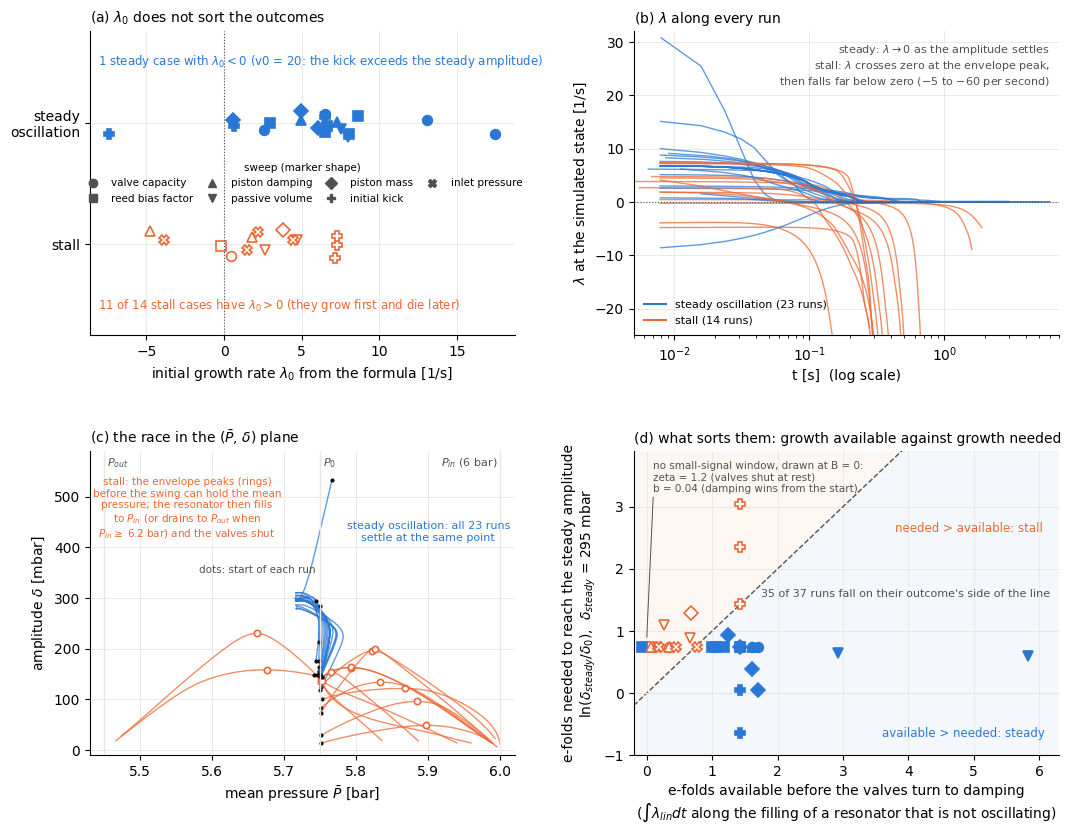

,sweep,value,outcome,lambda_0 formula [1/s],e-folds available B,window t_1 [s],e-folds needed,available - needed
0,m_max,0.00025,stall,0.46,0.33,0.77,0.74,-0.41
1,m_max,0.0005,steady,2.55,1.05,0.45,0.74,0.31
2,m_max,0.001,steady,6.53,1.42,0.22,0.74,0.68
3,m_max,0.002,steady,13.09,1.61,0.11,0.74,0.87
4,m_max,0.004,steady,17.48,1.70,0.06,0.74,0.96
5,zeta,0.4,stall,-0.22,0.03,0.39,0.74,-0.70
6,zeta,0.5,steady,2.95,1.06,0.40,0.74,0.32
7,zeta,0.6,steady,6.53,1.42,0.22,0.74,0.68
8,zeta,0.8,steady,8.65,1.00,0.10,0.74,0.26
9,zeta,1,steady,8.05,1.18,0.15,0.74,0.44


In [6]:
from matplotlib.lines import Line2D


def fill_budget(model, t_end=8.0):
    """Slow equations with no oscillation (a = 0): mean mass and pressure of the resonator as it fills, and the small-amplitude
    growth rate lambda_lin along that path, integrated until lambda_lin first turns negative.  Returns (B, t_1, no_window)."""
    M0 = model.P0 * model.V0_cv / (model.R * model.T0)

    def lam_lin(Mb, Pb):
        Vp, Vc, kcv, kp, w = model.geom(Pb); Tb = Pb * Vc / (Mb * model.R)
        return model.lam(Pb, Tb, (Vc - model.V0_cv) / model.A_neck, 0.0)[0]

    def rhs(t, y):
        Mb, Pb = y
        Vp, Vc, kcv, kp, w = model.geom(Pb); Tb = Pb * Vc / (Mb * model.R)
        F0i, F0o = model.reed(model.P_in - Pb), model.reed(Pb - model.P_out)
        return [F0i - F0o, model.Cf * (model.T_in * F0i - Tb * F0o) / (Vc + (model.gamma_E / model.gamma) * Vp)]

    def stop(t, y):
        return lam_lin(*y)
    stop.terminal = True; stop.direction = -1
    if lam_lin(M0, model.P0) < 0:
        return 0.0, 0.0, True
    sol = solve_ivp(rhs, (0.0, t_end), [M0, model.P0], method='LSODA', rtol=1e-7, atol=[1e-12, 1e-3],
                    dense_output=True, events=stop, max_step=5e-3)
    t1 = sol.t_events[0][0] if len(sol.t_events[0]) else sol.t[-1]
    ta = np.linspace(0.0, t1, 2001); Mb, Pb = sol.sol(ta)
    ll = np.array([lam_lin(Mb[i], Pb[i]) for i in range(len(ta))])
    return float(np.sum(0.5 * (ll[1:] + ll[:-1]) * np.diff(ta))), float(t1), False


# ---- growth available (B) and growth needed, one number each per run ----
delta_ss = float(np.median([kept[(r.sweep, r.value)]['half'][-1] for r in df.itertuples() if r.sustained]))
B, t1, nowin, need = [], [], [], []
for r in df.itertuples():
    model = Model(**{r.sweep: r.value})
    b_, t_, nw_ = fill_budget(model)
    d0 = model.geom(model.P0)[2] * model.v0 / model.geom(model.P0)[4] / model.A_neck
    B.append(b_); t1.append(t_); nowin.append(nw_); need.append(float(np.log(delta_ss / d0)))
df['B'], df['t1'], df['no_window'], df['need'] = B, t1, nowin, need
right = ((df.B > df.need) == df.sustained)
print('steady amplitude used: %.0f mbar   budget criterion right in %d of %d runs; misses: %s'
      % (delta_ss / 100, right.sum(), len(df), ', '.join('%s = %g' % (r.sweep, r.value) for r in df[~right].itertuples())))

# ---- figure ----
marks = dict(zip(SWEEPS, ['o', 's', '^', 'v', 'D', 'P', 'X']))
ccol = {True: BLUE, False: ORANGE}
n_steady, n_stall = int(df.sustained.sum()), int((~df.sustained).sum())
fig, axs = plt.subplots(2, 2, figsize=(12.5, 9.4)); fig.subplots_adjust(wspace=0.28, hspace=0.38)

# (a) initial growth rate against the outcome
ax = axs[0, 0]; rng = np.random.default_rng(3)
for r in df.itertuples():
    ax.plot(r.lam0_an, (1.0 if r.sustained else 0.0) + rng.uniform(-0.12, 0.12), marks[r.sweep], color=ccol[r.sustained],
            ms=7, mew=1.2, mfc=ccol[r.sustained] if r.sustained else 'white')
ax.axvline(0, color=INK2, lw=0.8, ls=':')
ax.set_yticks([0, 1]); ax.set_yticklabels(['stall', 'steady\noscillation']); ax.set_ylim(-0.75, 1.75)
ax.set_xlabel(r'initial growth rate $\lambda_0$ from the formula [1/s]')
ax.set_title(r'(a) $\lambda_0$ does not sort the outcomes', fontsize=10, loc='left')
n_st_pos = int(((~df.sustained) & (df.lam0_an > 0)).sum()); n_ok_neg = int((df.sustained & (df.lam0_an < 0)).sum())
ax.text(0.02, -0.5, '%d of %d stall cases have $\\lambda_0 > 0$ (they grow first and die later)' % (n_st_pos, n_stall),
        transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=8.5, color=ORANGE)
neg = ', '.join('%s = %g' % (r.sweep, r.value) for r in df[df.sustained & (df.lam0_an < 0)].itertuples())
ax.text(0.02, 1.5, '%d steady case with $\\lambda_0 < 0$ (%s: the kick exceeds the steady amplitude)' % (n_ok_neg, neg),
        transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=8.5, color=BLUE)
ax.legend(handles=[Line2D([], [], marker=marks[k], color=INK2, ls='', ms=6, label=SWEEPS[k][0].split('  ')[0]) for k in SWEEPS],
          frameon=False, fontsize=7.5, loc='center', ncol=4, title='sweep (marker shape)', title_fontsize=7.5, columnspacing=0.8)

# (b) lambda along every run
ax = axs[0, 1]
for r in df.itertuples():
    tr = kept[(r.sweep, r.value)]; L = tr['live']
    ax.plot(tr['tm'][L], tr['lam_an'][L], color=ccol[r.sustained], lw=1.0, alpha=0.75)
ax.set_xscale('log'); ax.axhline(0, color=INK2, lw=0.8, ls=':'); ax.set_ylim(-25, 32); ax.set_xlim(5e-3, 7)
ax.set_xlabel('t [s]  (log scale)'); ax.set_ylabel(r'$\lambda$ at the simulated state [1/s]')
ax.set_title(r'(b) $\lambda$ along every run', fontsize=10, loc='left')
ax.plot([], [], color=BLUE, lw=1.5, label='steady oscillation (%d runs)' % n_steady)
ax.plot([], [], color=ORANGE, lw=1.5, label='stall (%d runs)' % n_stall)
ax.legend(frameon=False, fontsize=8, loc='lower left')
ax.text(0.98, 0.96, r'steady: $\lambda \to 0$ as the amplitude settles' + '\n' + r'stall: $\lambda$ crosses zero at the envelope peak,' + '\n' + 'then falls far below zero ($-5$ to $-60$ per second)',
        transform=ax.transAxes, fontsize=8, va='top', ha='right', color=INK2)

# (c) paths in the (mean pressure, amplitude) plane
ax = axs[1, 0]
for r in df.itertuples():
    tr = kept[(r.sweep, r.value)]; L = tr['live']
    ax.plot(tr['Pm'][L] / 1e5, tr['half'][L] / 1e2, color=ccol[r.sustained], lw=1.0, alpha=0.75)
    ax.plot(tr['Pm'][0] / 1e5, tr['half'][0] / 1e2, '.', color=INK, ms=4)
    if not r.sustained:
        i = np.argmax(tr['half']); ax.plot(tr['Pm'][i] / 1e5, tr['half'][i] / 1e2, 'o', color=ORANGE, ms=4.5, mfc='white', mew=1.2)
for P, lab, ha in [(5.45, '$P_{out}$', 'left'), (5.75, '$P_0$', 'left'), (6.0, '$P_{in}$ (6 bar)', 'right')]:
    ax.axvline(P, color=GRID, lw=1); ax.text(P + (0.004 if ha == 'left' else -0.004), 560, lab, fontsize=8, color=INK2, ha=ha)
ax.set_xlim(5.43, 6.02); ax.set_ylim(-10, 590)
ax.set_xlabel(r'mean pressure $\bar P$ [bar]'); ax.set_ylabel(r'amplitude $\delta$ [mbar]')
ax.set_title(r'(c) the race in the ($\bar P$, $\delta$) plane', fontsize=10, loc='left')
ax.text(5.90, 430, 'steady oscillation: all %d runs\nsettle at the same point' % n_steady, fontsize=8, color=BLUE, ha='center', va='center')
ax.text(5.565, 475, 'stall: the envelope peaks (rings)\nbefore the swing can hold the mean\npressure; the resonator then fills\nto $P_{in}$ (or drains to $P_{out}$ when\n$P_{in} \\geq$ 6.2 bar) and the valves shut',
        fontsize=7.5, color=ORANGE, ha='center', va='center')
ax.text(5.744, 350, 'dots: start of each run', fontsize=7.5, color=INK2, ha='right')

# (d) growth available against growth needed
ax = axs[1, 1]
lim = (-0.2, 6.3); ax.plot(lim, lim, '--', color=INK2, lw=1); ax.set_xlim(lim); ax.set_ylim(-1.0, 3.9)
ax.fill_between(lim, lim, 3.9, color=ORANGE, alpha=0.05, lw=0); ax.fill_between(lim, -1.0, lim, color=BLUE, alpha=0.05, lw=0)
ax.axhline(0, color=GRID, lw=1)
for r in df.itertuples():
    xB = r.B if not r.no_window else (-0.07 if r.sweep == 'zeta' else 0.07)     # the two runs without a window, drawn side by side at B = 0
    ax.plot(xB, r.need, marks[r.sweep], color=ccol[r.sustained], ms=7, mew=1.2, mfc=ccol[r.sustained] if r.sustained else 'white')
ax.annotate('no small-signal window, drawn at B = 0:\nzeta = 1.2 (valves shut at rest)\nb = 0.04 (damping wins from the start)', (0.0, 0.9), xytext=(0.1, 3.2),
            fontsize=7.5, color=INK2, va='bottom', arrowprops=dict(arrowstyle='-', color=INK2, lw=0.7, shrinkA=0, shrinkB=0, relpos=(0.0, 0.0)))
ax.set_xlabel('e-folds available before the valves turn to damping\n' + r'($\int \lambda_{lin} dt$ along the filling of a resonator that is not oscillating)')
ax.set_ylabel('e-folds needed to reach the steady amplitude\n' + r'$\ln(\delta_{steady}/\delta_0)$,  $\delta_{steady}$ = %.0f mbar' % (delta_ss / 100))
ax.set_title('(d) what sorts them: growth available against growth needed', fontsize=10, loc='left')
ax.text(3.8, 2.6, 'needed > available: stall', fontsize=8.5, color=ORANGE)
ax.text(3.6, -0.7, 'available > needed: steady', fontsize=8.5, color=BLUE)
ax.text(0.98, 0.52, "%d of %d runs fall on their outcome's side of the line" % (right.sum(), len(df)), transform=ax.transAxes, ha='right', fontsize=8, color=INK2)
for a in axs.ravel():
    for sp in ['top', 'right']: a.spines[sp].set_visible(False)
    a.grid(color=GRID, lw=0.6, which='major')
plt.show()

# the numbers behind panel (d)
tab5 = df[['sweep', 'value', 'sustained', 'lam0_an', 'B', 't1', 'need']].copy()
tab5['outcome'] = np.where(tab5.sustained, 'steady', 'stall'); tab5['available - needed'] = tab5.B - tab5.need; tab5['value'] = ['%g' % v for v in tab5.value]
tab5 = tab5[['sweep', 'value', 'outcome', 'lam0_an', 'B', 't1', 'need', 'available - needed']]
tab5.columns = ['sweep', 'value', 'outcome', 'lambda_0 formula [1/s]', 'e-folds available B', 'window t_1 [s]', 'e-folds needed', 'available - needed']
tab5.round(2)

### Reading the figure

**(a)** The initial growth rates of the steady runs span $-7$ to $+17$ per second, those of the stall runs $-5$ to $+7$ per second: the two rows overlap over most of their range, so $\lambda_0$ on its own says little about the outcome. Eleven of the fourteen stall cases start out growing. The three that do not ($\zeta = 0.4$, $b = 0.04$, $P_{in} = 5.85$ bar) decay from the first cycle. The one steady case with $\lambda_0 \lt 0$ is the 20 m/s kick, whose amplitude starts above the steady one and decays down to it.

**(b)** In every steady run $\lambda$ falls to zero and stays there: the oscillation sits where $\lambda(\bar P, \delta) = 0$. In every stall run $\lambda$ passes through zero at the peak of the envelope and then drops far below zero — to about $-25$ to $-60$ per second in the fast cases, to $-5$ to $-9$ per second in the two slow ones ($\zeta = 0.4$ and $\dot m_{max} = 0.25$ g/s), whose envelope takes a second or more to die.

**(c)** The steady runs end at the same point whatever was swept: $\bar P = 5.72$ bar and $\delta = 0.28$ to $0.31$ bar. The mean pressure is held *below* the starting pressure $P_0 = 5.75$ bar by the oscillation itself: at $\bar P = P_0$ the reeds pass 0.34 g/s in and 0.28 g/s out without a swing, but 0.10 g/s in and 0.17 g/s out with a swing of 0.3 bar (the swing clips the inlet flow at both ends of the cycle), so a large oscillation empties the resonator until the balance is restored at a lower mean. The stall runs never get there. Their envelope peaks at 50 to 230 mbar while the mean pressure drifts away: toward $P_{in}$ in most cases, where the inlet reed has no pressure drop left to drive it; toward $P_{out}$ for the two runs with $P_{in} \geq 6.2$ bar, where the outlet already passes more than the inlet at $P_0$, the resonator drains, and on the way down the inlet drop grows beyond $\Delta P_{max}$ and presses the inlet reed shut. Either way the run ends with the valves shut or without a working pressure drop, and nothing drives the piston.

**(d)** The race made quantitative. Two slow processes compete: the oscillation grows at the rate $\lambda$, and the mean pressure drifts, which moves the working points of the reeds past the sign changes of their gains and takes the drive away after a time $t_1$. The number of e-folds available in that time, $B$, is what $\lambda$ contributes to the outcome; against it stands the number of e-folds the kick needs. Thirty-five of the 37 runs fall on their outcome's side of the line. The two that do not: $P_{in} = 6.2$ bar sits 0.03 e-folds on the wrong side (and $v_0 = 2.5$ m/s only 0.01 e-folds on the right side), so the criterion is not sharp at the few-hundredths level — the same softness as the 7 percent gap between the two models' kick thresholds in the sweep notebook; and $\zeta = 1.2$, where the budget as defined does not apply because there is no small-signal window at all (the valves are shut at the mean pressure and open only during the swing; the finite-amplitude $\lambda_0$ is $+6.6$ per second and the run is steady).

The sweeps read naturally in these terms. Along the valve-capacity sweep both $\lambda$ and $1/t_1$ scale with $\dot m_{max}$, so $B$ changes little (1.05 to 1.7 e-folds from 0.5 to 4 g/s, while $\lambda_0$ changes sevenfold) — but at the smallest capacity the damping term $-b/2m$, which does not scale, eats most of the budget (0.33 e-folds) and the run stalls. Along the kick sweep $B$ is fixed at 1.42 e-folds and only the need moves, from 3.0 e-folds at 0.5 m/s to $-0.65$ at 20 m/s; the threshold falls where need equals budget, at $v_0 \approx 2.5$ m/s, where the sweep notebook found it (2.5 m/s for the averaged model, 2.6 to 2.7 m/s for the full one). Along the passive-volume sweep the window $t_1$ lengthens with the passive volume (the piston yields more as the mean pressure rises, so the inlet has more volume to fill: 0.11 s to 0.67 s) and $B$ grows from 0.27 to 5.8 e-folds, which is why the two small passive volumes stall despite healthy initial growth rates of 2.7 and 4.7 per second. And the inlet-pressure sweep stalls on both sides of the baseline for different reasons: below it the window is short (the inlet reed starts close to the sign change of its gain, $t_1$ = 0.03 to 0.07 s); above it the resonator drains instead of filling, the outlet reed's working point drops below its flow peak and turns to damping, and the inlet reed is pressed shut.

So: $\lambda$ captures the growth at every instant, and the outcome is captured by $\lambda$ integrated over the time the resonator gives it — not by its initial value.

### 5.1 The budget in closed form

Everything in panel (d) can be written down by hand once the oscillation is dropped ($a = 0$), the piston is taken as quasi-static and the filling as isothermal ($\bar T \approx T_{in}$; in the base case $\bar T$ rises by 2.5 K and $\bar V_{cv}$ by 4 percent over the window, which is where the few-percent differences below come from).

**The growth rate at the start.** With $\delta \to 0$ the gains become the slopes of the flow law, $N_{in} \to -\dot m'(\Delta \bar P_{in})$ and $N_{out} \to +\dot m'(\Delta \bar P_{out})$, so $g_{lin} = -(\gamma R/\bar V_{cv})\left(T_{in}\dot m'(\Delta \bar P_{in}) + \bar T\dot m'(\Delta \bar P_{out})\right)$. With $\bar T = T_{in}$ and $c^2 = \gamma R T_{in}$ (the speed of sound squared, 348 m/s) this is

$$g_{lin} = \frac{c^2}{V_{cv}}\frac{d\dot m_{net}}{d\bar P}, \qquad \dot m_{net}(\bar P) = \dot m(P_{in} - \bar P) - \dot m(\bar P - P_{out}) \tag{5.1}$$

— the small-signal valve gain is the slope of the net inflow against the mean pressure. The reeds drive the oscillation exactly when a higher mean pressure lets more net gas in, and that is the same slope that makes the filling accelerate. For the flow law $\dot m = \dot m_{max}(1-u)\sqrt{u}$ the slope is $\dot m'(\Delta P) = (\dot m_{max}/\Delta P_{max})(1-3u)/(2\sqrt{u})$, so

$$\frac{d\dot m_{net}}{d\bar P} = \frac{\dot m_{max}}{2\Delta P_{max}}\left[\frac{3u_{in}-1}{\sqrt{u_{in}}} + \frac{3u_{out}-1}{\sqrt{u_{out}}}\right] \tag{5.2}$$

(a bracket term is dropped when its reed is shut, $u \geq 1$), and with $f = k_{cv}/(k_{cv}+k_{pass}) = \gamma_E V_{pass}/(\gamma_E V_{pass} + \gamma V_{cv})$ at the start,

$$\lambda_{lin}(0) = -\frac{b}{2m} + \frac{f}{2}\frac{c^2}{V_{cv}}\frac{d\dot m_{net}}{d\bar P} \tag{5.3}$$

Base case: $u_{in} = 0.545$, $u_{out} = 0.655$, bracket $= 0.862 + 1.191 = 2.053$; $\dot m_{max}/(2\Delta P_{max}) = 1.09 \times 10^{-8}$ kg/s per Pa, so $d\dot m_{net}/d\bar P = 2.24 \times 10^{-8}$ kg/s per Pa (0.22 g/s more net inflow per 0.1 bar); $c^2/V_{cv} = 1.21 \times 10^{9}$ gives $g_{lin} = 27.2$ per second; $f = 0.663$; $\lambda_{lin}(0) = -1.67 + 9.01 = 7.34$ per second, of which 3.78 comes from the inlet reed and 5.23 from the outlet reed.

**The integral.** Along the filling $d\bar P/dt = \dot m_{net}/C$ with $C = (V_{cv} + (\gamma_E/\gamma)V_{pass})/c^2$, so $dt = C d\bar P/\dot m_{net}$ and the drive part of the budget is

$$\int_0^{t_1}\frac{f c^2}{2V_{cv}}\frac{d\dot m_{net}}{d\bar P}dt = \frac{f c^2 C}{2V_{cv}}\int\frac{d\dot m_{net}}{\dot m_{net}} = \frac{\gamma_E V_{pass}}{2\gamma V_{cv}}\ln\frac{\dot m_{net}(t_1)}{\dot m_{net}(0)} \tag{5.4}$$

Hence

$$B = \frac{\gamma_E V_{pass}}{2\gamma V_{cv}}\ln\frac{\dot m_{net}(t_1)}{\dot m_{net}(0)} - \frac{b}{2m}t_1 \tag{5.5}$$

The window closes at the first of two events: $\lambda_{lin} = 0$, i.e. $d\dot m_{net}/d\bar P$ falling to $bV_{cv}/(m f c^2)$, or the outlet reed shutting at $\bar P = P_{out} + \Delta P_{max}$, where $d\dot m_{net}/d\bar P$ drops discontinuously. $t_1 = C\int d\bar P/\dot m_{net}(\bar P)$ is the filling time to that point — the one piece left as a quadrature (a one-line integral of an explicit function, no differential equation).

Base case: the window closes when the outlet shuts, at $\bar P = 5.908$ bar, where $\dot m_{net} = \dot m_{in}(u_{in} = 0.2) = 0.358$ g/s against $0.056$ g/s at the start: ratio 6.36, logarithm 1.85; $\gamma_E V_{pass}/(2\gamma V_{cv}) = 0.983$; drive part 1.82 e-folds. $t_1 = 0.223$ s, damping part $-0.37$. $B = 1.45$ against $1.42$ from the two slow equations integrated in full.

What (5.5) says: every e-fold by which the net inflow grows during the window buys $0.98$ e-folds of oscillation (for $V_{pass} = 2V_{cv}$), minus $b/2m$ per second of filling. The ratio $\dot m_{net}(t_1)/\dot m_{net}(0)$ does not contain $\dot m_{max}$ (why the valve capacity barely moves $B$); the prefactor is the volume ratio (why the passive volume matters so much); the damping enters only through the filling time (why the smallest capacity, with the longest filling, stalls). The table below applies (5.5) to all 37 settings and compares it with the budget integrated from the slow equations in section 5.

In [7]:
from scipy.integrate import quad
from scipy.optimize import brentq


def budget_closed_form(model):
    """B from (5.5): drive part in closed form, damping part from the filling time t_1 (one quadrature)."""
    c2 = model.gamma * model.R * model.T_in; Vc, Vp = model.V0_cv, model.V0_pass
    f = model.gamma_E * Vp / (model.gamma_E * Vp + model.gamma * Vc)
    pref = model.gamma_E * Vp / (2 * model.gamma * Vc)
    C = (Vc + (model.gamma_E / model.gamma) * Vp) / c2
    two_zeta = (model.P_in - model.P_out) / model.dP_max

    def flow(u):                       # (1-u) sqrt(u) while open, zero when pressed shut, reverse branch below zero
        return (1 - u) * np.sqrt(u) if 0 < u < 1 else (0.0 if u >= 1 else -(1 - u) * np.sqrt(-u))

    def dflow(u):
        return (1 - 3 * u) / (2 * np.sqrt(u)) if 0 < u < 1 else (0.0 if u >= 1 else (1 - 3 * u) / (2 * np.sqrt(max(-u, 1e-12))))

    D = lambda u: flow(two_zeta - u) - flow(u)            # net inflow / mdot_max, as a function of u = u_out (u_in = 2 zeta - u)
    dD = lambda u: -dflow(two_zeta - u) - dflow(u)        # times mdot_max / dP_max this is d mdot_net / d Pbar
    lam_lin = lambda u: -model.b_gas / (2 * model.m_gas) + 0.5 * f * (c2 / Vc) * (model.m_max / model.dP_max) * dD(u)
    u0 = (model.P0 - model.P_out) / model.dP_max
    if lam_lin(u0) < 0:
        return lam_lin(u0), 0.0, 0.0, 0.0, 0.0
    s = 1.0 if D(u0) > 0 else -1.0                        # filling (u_out grows) or draining
    uu = np.linspace(u0, u0 + s * 1.5, 30001); vals = np.array([lam_lin(u) for u in uu])
    j = np.where(vals < 0)[0][0]
    u1 = brentq(lam_lin, uu[j - 1], uu[j]) if lam_lin(uu[j - 1]) > 0 and lam_lin(uu[j]) < 0 and abs(vals[j] - vals[j - 1]) < 5 else uu[j]
    B_drive = pref * np.log(abs(D(u1 - s * 1e-9) / D(u0)))
    t1 = C * model.dP_max * abs(quad(lambda u: 1.0 / D(u), u0, u1, limit=200)[0]) / model.m_max
    B_damp = -model.b_gas / (2 * model.m_gas) * t1
    return lam_lin(u0), B_drive, B_damp, B_drive + B_damp, t1


rows = []
for r in df.itertuples():
    l0, Bd, Bb, Bc, t1c = budget_closed_form(Model(**{r.sweep: r.value}))
    rows.append(dict(sweep=r.sweep, value='%g' % r.value, outcome='steady' if r.sustained else 'stall', lam_lin0=l0, B_drive=Bd, B_damp=Bb,
                     B_closed=Bc, B_slow_eqs=r.B, diff=Bc - r.B, t1_closed=t1c, t1_slow_eqs=r.t1))
tab6 = pd.DataFrame(rows)
tab6.columns = ['sweep', 'value', 'outcome', 'lambda_lin(0) [1/s]', 'drive part (5.4)', 'damping part -b t_1/2m', 'B closed form (5.5)',
                'B from slow eqs', 'difference', 't_1 closed form [s]', 't_1 slow eqs [s]']
print('closed form against the slow equations: max |difference| in B = %.2f e-folds (%.2f without the two largest passive volumes)'
      % (tab6['difference'].abs().max(), tab6[~tab6.sweep.eq('V0_pass')]['difference'].abs().max()))
tab6.round(2)

closed form against the slow equations: max |difference| in B = 0.34 e-folds (0.03 without the two largest passive volumes)


,sweep,value,outcome,lambda_lin(0) [1/s],drive part (5.4),damping part -b t_1/2m,B closed form (5.5),B from slow eqs,difference,t_1 closed form [s],t_1 slow eqs [s]
0,m_max,0.00025,stall,0.59,1.67,-1.31,0.35,0.33,0.02,0.79,0.77
1,m_max,0.0005,steady,2.84,1.82,-0.74,1.08,1.05,0.03,0.45,0.45
2,m_max,0.001,steady,7.34,1.82,-0.37,1.45,1.42,0.02,0.22,0.22
3,m_max,0.002,steady,16.35,1.82,-0.19,1.63,1.61,0.02,0.11,0.11
4,m_max,0.004,steady,34.37,1.82,-0.09,1.73,1.70,0.02,0.06,0.06
5,zeta,0.4,stall,0.14,0.71,-0.67,0.04,0.03,0.00,0.40,0.39
6,zeta,0.5,steady,3.46,1.73,-0.66,1.08,1.06,0.02,0.39,0.40
7,zeta,0.6,steady,7.34,1.82,-0.37,1.45,1.42,0.02,0.22,0.22
8,zeta,0.8,steady,16.58,1.19,-0.17,1.01,1.00,0.01,0.10,0.10
9,zeta,1,steady,11.58,1.46,-0.26,1.20,1.18,0.02,0.15,0.15
